# Polynomial Regression Using Different Optimization Algorithms

In [1]:
!pip install ucimlrepo

## 1. Import Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Loading

In [3]:
try:
    # Primary source: UCI (internet)
    auto_mpg = fetch_ucirepo(id=9)
    X_data = auto_mpg.data.features
    y_data = auto_mpg.data.targets

    df = X_data.copy()
    df["mpg"] = y_data["mpg"]

    print("Loaded from UCI (internet)")

except Exception as e:
    # Backup source: Kaggle Dataset
    print("UCI failed, loading Kaggle backup:", e)

    import os

    for root, dirs, files in os.walk("/kaggle/input"):
        if "auto-mpg.data" in files:
            backup_path = os.path.join(root, "auto-mpg.data")
            break

    df = pd.read_csv(
        backup_path,
        names=["mpg", "cylinders", "displacement", "horsepower",
               "weight", "acceleration", "model_year", "origin", "car_name"],
        na_values="?",
        sep=r"\s+",
        skipinitialspace=True
    )

df = df[["horsepower", "mpg"]]

df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df["mpg"] = pd.to_numeric(df["mpg"], errors="coerce")

display(df.head())
print("Dataset shape:", df.shape)

Loaded from UCI (internet)


,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0


Dataset shape: (398, 2)


## 3. Exploratory Data Analysis (EDA)

In [4]:
# Dataset Information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   horsepower  392 non-null    float64
 1   mpg         398 non-null    float64
dtypes: float64(2)
memory usage: 6.3 KB

Statistical Summary:


,horsepower,mpg
count,392.000000,398.000000
mean,104.469388,23.514573
std,38.491160,7.815984
min,46.000000,9.000000
25%,75.000000,17.500000
50%,93.500000,23.000000
75%,126.000000,29.000000
max,230.000000,46.600000



Missing Values:
horsepower    6
mpg           0
dtype: int64


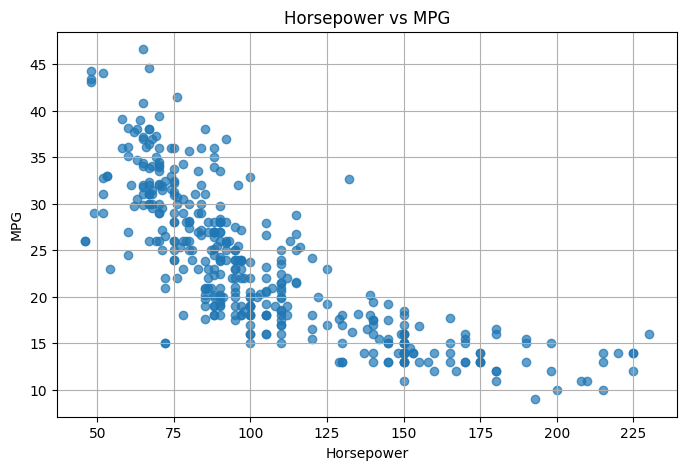

In [5]:

plt.figure(figsize=(8, 5))

plt.scatter(df["horsepower"], df["mpg"], alpha=0.7)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Horsepower vs MPG")

plt.grid(True)
plt.show()


## 4. Data Preprocessing

4.1 Separate Features and Target

4.2 Split Data into Training and Testing Sets

4.3 Handle Missing Values

4.4 Polynomial Feature Transformation

4.5 Feature Scaling

4.6 Add Bias Term

In [6]:

X = df[["horsepower"]].values
y = df[["mpg"]].values

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (398, 1)
y shape: (398, 1)


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 318
Testing samples: 80


In [8]:

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Missing values handled successfully!")


Missing values handled successfully!


In [9]:

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original features:", X_train.shape)
print("Polynomial features:", X_train_poly.shape)

print("\nFirst 5 polynomial samples:")
print(X_train_poly[:5])


Original features: (318, 1)
Polynomial features: (318, 2)

First 5 polynomial samples:
[[  150. 22500.]
 [   88.  7744.]
 [   68.  4624.]
 [   60.  3600.]
 [   95.  9025.]]


In [10]:

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Scale the target values too
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

print("Feature scaling completed!")


Feature scaling completed!


In [11]:

# Add bias column to training and testing data

X_train_model = np.c_[
    np.ones((X_train_scaled.shape[0], 1)),
    X_train_scaled
]

X_test_model = np.c_[
    np.ones((X_test_scaled.shape[0], 1)),
    X_test_scaled
]

print("Training shape:", X_train_model.shape)
print("Testing shape:", X_test_model.shape)


Training shape: (318, 3)
Testing shape: (80, 3)


## 5. Model and Loss Function

In [12]:

# Initialize model parameters

n_features = X_train_model.shape[1]

initial_weights = np.zeros((n_features, 1))

print("Initial weights:")
print(initial_weights)


Initial weights:
[[0.]
 [0.]
 [0.]]


In [13]:

def compute_loss(X, y, weights):

    predictions = X @ weights

    #Mean Squared Error (MSE)
    loss = np.mean((predictions - y) ** 2)

    return loss


## 6. Optimization Algorithm

6.3 MiniBatch Gradient Descent 


In [14]:

def compute_gradient(X, y, weights):

    m = len(y)

    predictions = X @ weights

    gradient = (2 / m) * X.T @ (predictions - y)

    return gradient


## 7. Train the Model

In [15]:
def train_minibatch(batch_size=32, learning_rate=0.01,
                    epochs=500, use_momentum=False, beta=0.9, seed=42):

    weights = np.zeros((X_train_model.shape[1], 1))
    velocity = np.zeros_like(weights)

    loss_history = []

    # Same seed -> both runs (with / without momentum) see the same shuffles
    rng = np.random.default_rng(seed)

    start_time = time.time()

    m = len(y_train_scaled)

    for epoch in range(epochs):

        # Shuffle training data
        indices = rng.permutation(m)
        X_shuffled = X_train_model[indices]
        y_shuffled = y_train_scaled[indices]

        # Process mini-batches
        for i in range(0, m, batch_size):

            X_batch = X_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            gradient = compute_gradient(
                X_batch,
                y_batch,
                weights
            )

            if use_momentum:
                velocity = beta * velocity + gradient
                weights -= learning_rate * velocity
            else:
                weights -= learning_rate * gradient

        epoch_loss = compute_loss(
            X_train_model,
            y_train_scaled,
            weights
        )

        loss_history.append(epoch_loss)

    training_time = time.time() - start_time

    return weights, loss_history, training_time

In [16]:
# 1. Mini-Batch GD without Momentum
weights_minibatch, loss_history_minibatch, training_time_minibatch = train_minibatch(
    use_momentum=False
)

# 2. Mini-Batch GD with Momentum
weights_momentum, loss_history_momentum, training_time_momentum = train_minibatch(
    use_momentum=True
)

# Print Results
print("Mini-Batch GD Final Loss:", loss_history_minibatch[-1])
print("Mini-Batch GD Training Time:", training_time_minibatch)
print("Mini-Batch GD Final Weights:")
print(weights_minibatch)

print("\nMini-Batch GD + Momentum Final Loss:", loss_history_momentum[-1])
print("Mini-Batch GD + Momentum Training Time:", training_time_momentum)
print("Mini-Batch GD + Momentum Final Weights:")
print(weights_momentum)

Mini-Batch GD Final Loss: 0.3403771817322366
Mini-Batch GD Training Time: 0.06599044799804688
Mini-Batch GD Final Weights:
[[ 7.24726063e-04]
 [-1.89294540e+00]
 [ 1.15134506e+00]]

Mini-Batch GD + Momentum Final Loss: 0.33713497457785363
Mini-Batch GD + Momentum Training Time: 0.0662238597869873
Mini-Batch GD + Momentum Final Weights:
[[-0.00807145]
 [-2.20537725]
 [ 1.4820036 ]]


## 8. Visualizing Training Loss

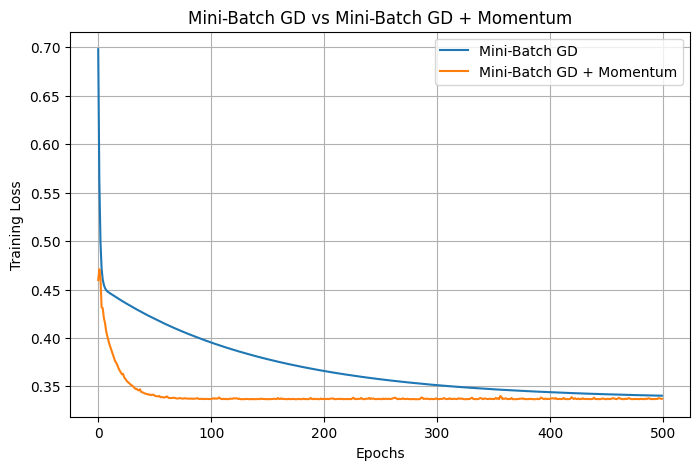

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history_minibatch, label="Mini-Batch GD")
plt.plot(loss_history_momentum, label="Mini-Batch GD + Momentum")

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Mini-Batch GD vs Mini-Batch GD + Momentum")

plt.legend()
plt.grid(True)
plt.show()

## 9. Model Evaluation

In [18]:
# Predictions using Mini-Batch GD
y_pred_minibatch_scaled = X_test_model @ weights_minibatch

# Predictions using Mini-Batch GD + Momentum
y_pred_momentum_scaled = X_test_model @ weights_momentum

# Convert predictions back to original scale
y_pred_minibatch = scaler_y.inverse_transform(y_pred_minibatch_scaled)
y_pred_momentum = scaler_y.inverse_transform(y_pred_momentum_scaled)

# Evaluate Mini-Batch GD
print("Mini-Batch GD Evaluation:")
print("MSE:", mean_squared_error(y_test, y_pred_minibatch))
print("MAE:", mean_absolute_error(y_test, y_pred_minibatch))
print("R2 Score:", r2_score(y_test, y_pred_minibatch))

# Evaluate Mini-Batch GD + Momentum
print("\nMini-Batch GD + Momentum Evaluation:")
print("MSE:", mean_squared_error(y_test, y_pred_momentum))
print("MAE:", mean_absolute_error(y_test, y_pred_momentum))
print("R2 Score:", r2_score(y_test, y_pred_momentum))

Mini-Batch GD Evaluation:
MSE: 13.970932068066116
MAE: 2.9778728113238913
R2 Score: 0.7401551768417618

Mini-Batch GD + Momentum Evaluation:
MSE: 13.95858547816079
MAE: 2.920226084179181
R2 Score: 0.740384810588095


## 10. Compare Results

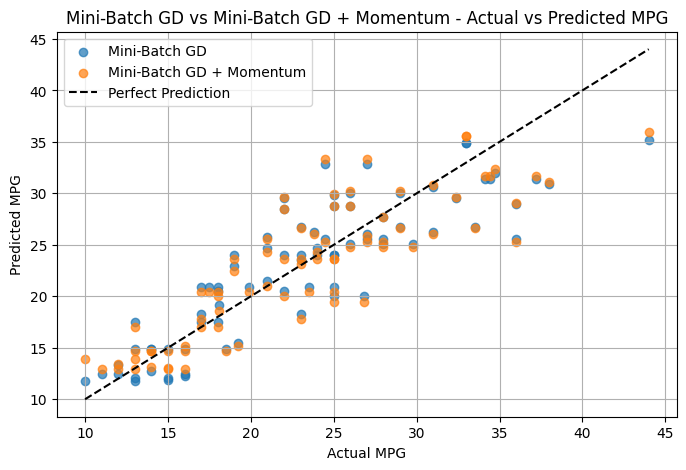

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_minibatch, label="Mini-Batch GD", alpha=0.7)
plt.scatter(y_test, y_pred_momentum, label="Mini-Batch GD + Momentum", alpha=0.7)

# Perfect prediction line
min_value = y_test.min()
max_value = y_test.max()

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'k--',
    label="Perfect Prediction"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Mini-Batch GD vs Mini-Batch GD + Momentum - Actual vs Predicted MPG")

plt.legend()
plt.grid(True)
plt.show()

## Conclusion

In this notebook, Polynomial Regression (degree 2) was implemented using Mini-Batch Gradient Descent (batch size 32) to predict fuel efficiency (MPG) from horsepower. The same dataset and preprocessing steps were used to maintain consistency with the previous experiments.

Two experiments were conducted: Mini-Batch GD without Momentum and with Momentum. Data is reshuffled every epoch with a fixed seed, so results are reproducible. Mini-batches give far more updates per epoch than full-batch GD (10 per epoch here) with much less noise than single-sample SGD, so training reaches the minimum quickly and stably; momentum speeds this up slightly.

The models were evaluated with MSE, MAE and R² on the test set, and loss curves and actual-vs-predicted plots were used to compare them. Re-run the notebook for the final numbers.